<a href="https://pulse.simudyne.com"><img src="_notebook_assets/Simudyne_Symbol_Logotype_BLUE_RGB.png" width="320" alt="Simudyne"></a>

# Run Pulse on a day you choose

> **Simudyne Pulse · Production** — runs against `https://pulse-api.simudyne.com` with the `simudyne-pulse` SDK.

Prompt the foundation model with a real trading day from the Pulse catalogue. The model starts from that day's real book and generates the continuation.

📖 **Docs:** [Foundation models](https://pulse.simudyne.com/docs/foundation-models) · [Download data](https://pulse.simudyne.com/docs/available-data) · [Errors](https://pulse.simudyne.com/docs/errors)

### Setup

`pip install simudyne-pulse` and set your key — `export SIMUDYNE_API_KEY=pk_live_...`, or pass
`PulseABM(api_key=...)`. Keys come from your [account page](https://pulse.simudyne.com/docs/api-keys); see
[Authentication](https://pulse.simudyne.com/docs/authentication).

A production run is a **job**: `run()` returns at once with a `job_id`, the model runs on
Pulse's compute, and `wait()` below polls it every 20 seconds until it finishes.

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output
from simudyne import PulseABM

client = PulseABM()   # reads SIMUDYNE_API_KEY; points at production by default


def wait(job_id, every=20):
    """Poll a job until every run has finished and its results can be read."""
    start = time.time()
    while True:
        status = client.simulation.get_job_status(job_id)
        clear_output(wait=True)
        note = "" if status["is_complete"] else status.get("message") or ""
        print(f"{job_id}  {time.time() - start:4.0f}s  {status['status_summary']}  {note}")
        if status["is_complete"]:
            sims = client.simulation.get_job_results(job_id)["simulations"]
            if all(s.get("metrics") or s["status"] in ("error", "failed") for s in sims):
                break
        time.sleep(every)
    if status["has_errors"]:
        print(client.simulation.get_job_logs(job_id)[-2000:])
    return status


def generated(sim_id):
    """The model's own rows: sim_data.parquet minus the real warm-start context."""
    book = client.simulation.get_sim_data(sim_id)
    segments = client.simulation.get_sim_metrics(sim_id)["segments"]
    return pl.concat([book.slice(a, b - a) for a, b in (s["generated"] for s in segments)])


def mid(frame):
    return frame.select("timestamp", mid=(pl.col("bid_price_1") + pl.col("ask_price_1")) / 2)


def style(ax, title, ylabel="mid"):
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.margins(x=0)

## 1. Find a model and the data it supports

Start from a model to see its markets, or from a market to find a model.
See [Data to prompt with](https://pulse.simudyne.com/docs/foundation-models).

In [2]:
models = client.fm.models()["models"]

for m in models:
    print(m["production_name"], "→", m["supported_data"])

flow-hkex-1-100M → [{'provider': 'bmll', 'exchange': 'hkex_securities'}]
flow-lse-1-100M → [{'provider': 'bmll', 'exchange': 'lse'}]
flow-lse-1-54M → [{'provider': 'bmll', 'exchange': 'lse'}]


In [3]:
# Which model supports a given exchange?
exchange = "lse"

print([m["production_name"] for m in models if any(d["exchange"] == exchange for d in m["supported_data"])])

MODEL = "flow-lse-1-54M"   # pick one by name: the public LSE model

['flow-lse-1-100M', 'flow-lse-1-54M']


## 2. Pick a symbol-day

`available_data(model_id=...)` lists only the days that model will accept, so anything it
returns is a valid input to `run()`.

In [4]:
hits = client.data.available_data(model_id=MODEL, symbol="TSCO")
tsco = hits["symbols"][0]

print(tsco["provider"], tsco["exchange"], tsco["symbol"], "—", len(tsco["dates"]), "days")
print("latest:", tsco["dates"][-5:])

bmll lse TSCO — 254 days
latest: ['2026-06-17', '2026-06-18', '2026-06-19', '2026-06-22', '2026-06-23']


In [5]:
PROVIDER, EXCHANGE = tsco["provider"], tsco["exchange"]
SYMBOL = "TSCO"
DATE = "2025-09-01"
assert DATE in tsco["dates"]

## 3. Run it

Name all four of `symbol`, `cal_date`, `provider` and `exchange` — they are all-or-nothing on a
foundation-model run, and they are checked against the catalogue before the job is accepted.

In [6]:
job = client.simulation.run(
    engine="fm", model_id=MODEL,
    symbol=SYMBOL, cal_date=DATE, provider=PROVIDER, exchange=EXCHANGE,
    duration_minutes=15, n_runs=3, seed=42,
)
status = wait(job["job_id"])

4ead2764-7586-46f1-a8a4-c89fb0b4f237   314s  {'complete': 3}  


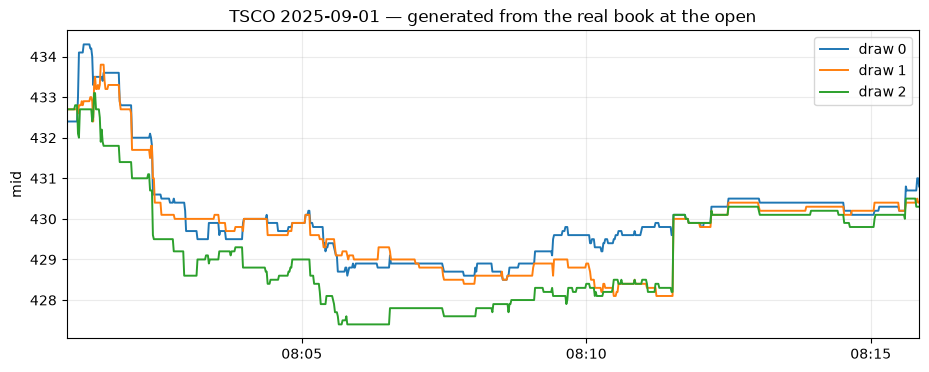

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))

for i, sim_id in enumerate(job["sim_ids"]):
    m = mid(generated(sim_id))
    ax.plot(m["timestamp"], m["mid"], lw=1.4, label=f"draw {i}")

style(ax, f"{SYMBOL} {DATE} — generated from the real book at the open")
ax.legend();

The run starts from the real book state at the window's open; where it goes from there is the
model. Timestamps are exchange **local** time throughout.

`get_sim_params()` records the identity the API resolved — your venue, symbol and date —
alongside every resolved knob, and the metrics give the window that was generated:

In [8]:
sim_id = job["sim_ids"][0]
params = client.simulation.get_sim_params(sim_id)["sim_params"]
metrics = client.simulation.get_sim_metrics(sim_id)

print(metrics["generated_window"])
params

{'start': '2025-09-01T08:00:52', 'end': '2025-09-01T08:15:51'}


{'sim_param_hash': '14995c9a',
 'mc_number': 0,
 'seed': 42,
 'horizon_minutes': 15.0,
 'horizon_frames': None,
 'device': 'cpu',
 'model_id': 'flob-adaln-rf-1s-lse-54m',
 'model_version': '1.0.2',
 'gen_method': 'FM-flob-adaln-rf-1s-lse-54m_v1.0.2',
 'model_args': {'num_steps': 10,
  'method': 'euler',
  'guidance': 1.0,
  'historical_conditions': True,
  'null_future_conditions': False,
  'refresh_cycle': 20,
  'impact_model': 'resilience',
  'impact_seconds': 10.0,
  'impact_coefficient': 1.0},
 'generated_window': {'start': '2025-09-01T08:00:52',
  'end': '2025-09-01T08:15:51'},
 'sessions': ['Continuous']}

## 4. Draws side by side

Every draw starts from the same book and seed-derived randomness, so the spread across them is
the model's uncertainty about the next fifteen minutes.

In [9]:
results = client.simulation.get_job_results(job["job_id"])

pl.DataFrame([
    {"draw": i, "n_generated": s["metrics"].get("n_generated"),
     "total_trades": s["metrics"].get("total_trades"), "compute_time_s": s["metrics"].get("compute_time_s")}
    for i, s in enumerate(results["simulations"])
])

draw,n_generated,total_trades,compute_time_s
i64,i64,i64,f64
0,900,0,300.36
1,900,0,300.36
2,900,0,300.36


---

## If it is rejected

A bad request fails in milliseconds with a `PulseAPIError` naming the field, before any compute
starts. For example, a market the model was not trained on:

In [10]:
from simudyne.exceptions import PulseAPIError

try:
    client.simulation.run(engine="fm", model_id=MODEL, symbol="700", cal_date=DATE,
                          provider="bmll", exchange="hkex_securities")
except PulseAPIError as e:
    print(e.status_code, e)

422 API Error (422): model 'flob-adaln-rf-1s-lse-54m' does not accept data from bmll:hkex_securities; it supports bmll:lse. GET /data/available-data?model_id=flob-adaln-rf-1s-lse-54m lists the symbol-days it can be prompted with.


| Status | Meaning |
|---|---|
| `422` naming missing fields | only some of `symbol`/`cal_date`/`provider`/`exchange` were given |
| `422` listing supported markets | the model does not accept that venue |
| `422` listing dates that exist | no data for that day |
| `403` | the key is not Pro tier |

Every status code: [Errors](https://pulse.simudyne.com/docs/errors).